<a href="https://colab.research.google.com/github/mahmoudabdalaty00/Py_Trainning/blob/main/Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Basic_Neural_Network


In [114]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [115]:
#create a model class that inherit nn.module
class Model(nn.Module):
  #--> input layer (4 features of the flow )
  #--> hidden layer 1(number of neurons)
  #--> h2 (n)
  #--> output(3 classes of iris flow)
  def __init__(self,in_features=4,h1=8,h2=9,out_features=3):
    super().__init__() #instance our nn model
    self.fc1=nn.Linear(in_features,h1)
    self.fc2=nn.Linear(h1,h2)
    self.out=nn.Linear(h2,out_features)


  def forward(self,x):
    x=F.relu(self.fc1(x))
    x=F.relu(self.fc2(x))
    x=self.out(x)
    return x




In [116]:
#peek a mahual seed for randomization
torch.manual_seed(41)
#create instance of model
model=Model()

Train_Neural_Network



In [117]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [118]:
url = 'https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv'
my_df =pd.read_csv(url)

In [119]:
# 1. Clean all column headers of hidden spaces
my_df.columns = my_df.columns.str.strip()

# 2. Check available columns
print("Available columns:", my_df.columns.tolist())

Available columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [120]:
my_df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [121]:
my_df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [122]:
#change last column from string to int
#my_df['species'] = my_df['species'].replace('versicolor', 1.0)
#my_df['species'] = my_df['species'].replace('virginica', 2.0)
#my_df['species'] = my_df['species'].replace('setosa', 0.0)
# or
my_df['species'] = my_df['species'].map({'versicolor': 1.0, 'virginica': 2.0, 'setosa': 0.0})
my_df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


In [123]:
# Train Test Split! Set X,Y
X = my_df.drop('species',axis=1)
Y = my_df['species']

In [124]:
# convert these to numpy arrays
X = X.values
Y = Y.values

In [125]:
from sklearn.model_selection import train_test_split

In [126]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=41)

In [127]:
# Convert X features to float tensor
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)


In [128]:
# Convert Y features to tensors long
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)


In [129]:
#Set the criterion of model to measure the error
# how far off the predictions are from the data
criterion = nn.CrossEntropyLoss()
#Chooss Adam optimizsr,
#lr = learning rate  -->(if error dosent do gown after a bunch of iterations (epochs),...)
optimizer = torch.optim.Adam(model.parameters(),lr=0.01)

In [130]:
model

Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)

In [131]:
#train our model !
# Epochs ? (one run throgh all the training data in our network)
epochs = 100
losses = []
for i in range(epochs) :
 #go forward and get predication
 y_pred = model.forward(X_train)

 # measure the losses ,errors , gonne be high at first
 loss = criterion(y_pred,y_train)

 #keep track our losses
 losses.append(loss.detach().numpy())

 if i % 10 == 0 :
  print(f'epoch : {i} and losses : {loss}')

 optimizer.zero_grad()
 loss.backward()
 optimizer.step()

epoch : 0 and losses : 1.1251550912857056
epoch : 10 and losses : 1.0096259117126465
epoch : 20 and losses : 0.8157405853271484
epoch : 30 and losses : 0.585706353187561
epoch : 40 and losses : 0.3999636471271515
epoch : 50 and losses : 0.26768800616264343
epoch : 60 and losses : 0.17942364513874054
epoch : 70 and losses : 0.12151692062616348
epoch : 80 and losses : 0.0860118493437767
epoch : 90 and losses : 0.06520849466323853


Text(0.5, 0, 'Epoch')

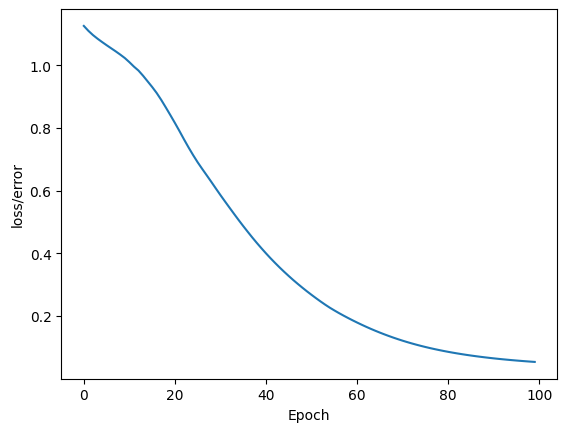

In [132]:
#Graph it out
 plt.plot(range(epochs),losses)
 plt.ylabel('loss/erroe')
 plt.xlabel('Epoch')

Evaluate Model On Test Data Set

In [133]:
#Evaluate Model On Test Data Set(Validate model on test set )
with torch.no_grad():   #basically turn off back propogation
 y_eval = model.forward(X_test) # x_test are features from our test set , y_eval will be predications
 loss =criterion(y_eval,y_test) # find the loss or error


In [134]:
loss

tensor(0.1315)

In [135]:
correct = 0
with torch.no_grad():
  for i,data in enumerate(X_test):
    y_val = model.forward(data)

    if y_test[i] == 0 :
      x = 'setosa'
    elif y_test[i] == 1 :
      x = 'versicolor'
    else :
      x = 'virginica'

    #will tell us what type of flower our network thinks it is
    print(f'{i+1}.) {str(y_val)} \t  {x} \t {y_val.argmax().item()} ')

    #correct or not
    if y_val.argmax().item() == y_test[i] :
      correct +=1
print(f'we got {correct} correct')


1.) tensor([-5.8760,  4.4628,  6.5124]) 	  virginica 	 2 
2.) tensor([-7.5436,  4.1670,  9.7255]) 	  virginica 	 2 
3.) tensor([-8.4504,  5.1271, 10.1987]) 	  virginica 	 2 
4.) tensor([-4.3398,  5.6267,  2.5608]) 	  versicolor 	 1 
5.) tensor([-7.1825,  4.8754,  8.2992]) 	  virginica 	 2 
6.) tensor([-3.3974,  5.3463,  1.2803]) 	  versicolor 	 1 
7.) tensor([-5.9231,  4.9822,  5.9997]) 	  virginica 	 2 
8.) tensor([-4.2881,  5.7003,  2.3889]) 	  versicolor 	 1 
9.) tensor([-6.5356,  4.9257,  7.1260]) 	  virginica 	 2 
10.) tensor([-8.0509,  4.4129, 10.3286]) 	  virginica 	 2 
11.) tensor([-5.6762,  4.9500,  5.6215]) 	  virginica 	 2 
12.) tensor([ 4.5662, -2.2476, -2.8911]) 	  setosa 	 0 
13.) tensor([ 4.2571, -1.9967, -2.7330]) 	  setosa 	 0 
14.) tensor([-2.1108,  4.0515,  0.5799]) 	  versicolor 	 1 
15.) tensor([ 3.4575, -1.2098, -2.3514]) 	  setosa 	 0 
16.) tensor([-5.4724,  5.1165,  5.0934]) 	  virginica 	 1 
17.) tensor([ 4.0557, -1.7949, -2.6492]) 	  setosa 	 0 
18.) tensor([-

Evaluate New Data On The Network

In [136]:
new_iris = torch.tensor([4.7,3.2,1.3,0.2])

In [137]:
with torch.no_grad() :
 print( model(new_iris))

tensor([ 4.5365, -2.2383, -2.8684])


In [138]:
newer_iris = torch.tensor([5.9,3.0,5.1,1.8])

In [139]:
with torch.no_grad() :
 print( model(newer_iris))

tensor([-5.9944,  4.5077,  6.6792])


Save Our NN Model

In [141]:
#save our model
torch.save(model.state_dict(),'iris_model.pt')

In [142]:
#load the saved model
new_model = Model()
new_model.load_state_dict(torch.load('iris_model.pt'))

<All keys matched successfully>

In [144]:
#make sure it load correct
new_model.eval()

Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)